# 국면 기반 TDF 백테스트 — 이진 전환 vs relevance 연속 반영

**목적**: Kritzman(2017) 국면 기반 TDF의 아이디어를 세 가지 전략으로 비교한다.

| 전략 | 주식 비중 결정 |
|---|---|
| 정적 글라이드 | 남은 기간 $\tau$만으로 결정 |
| 이진 전환 | turbulence가 80분위를 넘으면 밴드 하단으로 감축 (Kritzman 2017 방식) |
| relevance 연속 | 상태벡터의 relevance로 조건부 $\mu,\Sigma$ 추정 → 글라이드 주변에서 연속 조정 |

**상태벡터**: turbulence 크기·상관 성분, $\Delta AR$, 거품 단계 대용(run-up·drawdown)

**데이터**: yfinance로 Vanguard 뮤추얼펀드 7종(1996~)을 내려받는다. 다운로드가 막히면 2-상태 합성 데이터로 자동 대체한다(코드 검증용).

> 실행 순서: 위에서부터 차례로 실행. Colab 기준 약 1~2분.

In [1]:
!pip install -q yfinance

## 0. 설정과 데이터

- 위험자산 슬리브: 미국·선진국·신흥국 주식 동일가중
- 안전자산 슬리브: 중기 국채·투자등급 회사채 동일가중
- 상태변수 계산에는 7개 자산 전부(장기 국채·귀금속 포함)를 쓴다
- `TARGET_DATE`는 가상 빈티지의 목표일이다. 2002년 시작 시점에 남은 기간 약 25년

In [2]:
# ===== 0. 설정 =====
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
warnings.filterwarnings("ignore")

# 장기 이력이 있는 Vanguard 뮤추얼펀드(1990년대부터) — 자산군 대용
TICKERS = {
    "VFINX": "US Equity", "VGTSX": "Intl Equity", "VEIEX": "EM Equity",
    "VFITX": "Int Treasury", "VUSTX": "Long Treasury", "VWESX": "IG Credit",
    "VGPMX": "Precious Metals",
}
EQ_SLEEVE = ["VFINX", "VGTSX", "VEIEX"]        # 위험자산 슬리브(동일가중)
BD_SLEEVE = ["VFITX", "VWESX"]                  # 안전자산 슬리브(동일가중)
START, TARGET_DATE = "1996-06-01", "2027-01-31" # TARGET_DATE = 가상 빈티지 목표일

TURB_WIN   = 750    # turbulence 평균·공분산 추정 창(거래일)
AR_WIN     = 500    # absorption ratio 공분산 창
AR_HL      = 250    # AR 지수가중 반감기
TRADE_FROM = "2002-01-31"
Q_KEEP     = 0.25   # relevance 상위 25%만 사용(partial sample)
BINARY_PCT = 0.80   # 이진 전략: turbulence 80분위 초과 = event
NO_TRADE   = 0.02   # no-trade 밴드(2%p)
MU_SHRINK  = 0.25   # 조건부 기대수익을 무조건부 평균 쪽으로 수축(25%만 반영)
SMOOTH     = 0.5    # 기울기(tilt) 지수평활 계수
COST_BP    = 10     # 편도 거래비용(bp)



# ===== 1. 데이터 =====
def load_prices():
    try:
        import yfinance as yf, logging
        logging.getLogger("yfinance").setLevel(logging.CRITICAL)
        px = yf.download(list(TICKERS), start=START, auto_adjust=True,
                         progress=False)["Close"]
        px = px.dropna(how="any")
        if len(px) < 2000:
            raise ValueError("데이터 부족")
        return px, "yfinance"
    except Exception as e:
        print("yfinance 실패 → 합성 데이터로 대체:", e)
        return synthetic_prices(), "synthetic"


def synthetic_prices(seed=7):
    """2-상태 Markov 국면(평온·위기)을 가진 합성 일별 가격 — 코드 검증용."""
    rng = np.random.default_rng(seed)
    idx = pd.bdate_range(START, "2026-09-30")
    n, N = len(idx), len(TICKERS)
    mu_c = np.array([.0004, .0003, .0004, .00015, .0002, .00018, .0002])
    vol_c = np.array([.009, .010, .013, .003, .008, .004, .015])
    vol_s = vol_c * np.array([3, 3, 3.2, 1.3, 1.6, 1.8, 2])
    mu_s = np.array([-.0025, -.0025, -.003, .0004, .0006, -.0002, .0003])
    rho_c, rho_s = .35, .80
    def cov(vol, rho, flight):
        C = np.full((N, N), rho); np.fill_diagonal(C, 1)
        C[:3, 3:5] = C[3:5, :3] = -0.3 if flight else 0.0   # 위기: 안전자산 도피
        return np.outer(vol, vol) * C
    Lc = np.linalg.cholesky(cov(vol_c, rho_c, False) + 1e-12 * np.eye(N))
    Ls = np.linalg.cholesky(cov(vol_s, rho_s, True) + 1e-12 * np.eye(N))
    P = np.array([[0.996, 0.004], [0.02, 0.98]])
    s, R = 0, np.empty((n, N))
    for t in range(n):
        s = rng.choice(2, p=P[s])
        z = rng.standard_normal(N)
        R[t] = (mu_c + Lc @ z) if s == 0 else (mu_s + Ls @ z)
    return pd.DataFrame(100 * np.exp(np.cumsum(R, 0)), idx, list(TICKERS))



px, SRC = load_prices()
print(SRC, px.shape, px.index[0].date(), '~', px.index[-1].date())

yfinance (7644, 7) 1996-06-03 ~ 2026-10-19


## 1. 상태변수

**Turbulence** (Kritzman–Li 2010)와 **Kinlaw–Turkington(2014) 분해**

$$d_t=\frac{1}{N}(r_t-\mu)^\top\Sigma^{-1}(r_t-\mu),\qquad
\text{mag}_t=\frac{1}{N}\sum_j \frac{(r_{jt}-\mu_j)^2}{\sigma_j^2},\qquad
\text{corr}_t=\frac{d_t}{\text{mag}_t}$$

- 크기 성분은 상관을 무시한(대각 공분산) 이례성이다
- 상관 surprise가 1보다 크면 평소 상관 구조가 깨졌다는 뜻이다

**Absorption ratio** (Kritzman·Li·Page·Rigobon 2011): 고유벡터 수 $n=\lceil N/5\rceil$, 지수가중 공분산(반감기 250일)

$$AR_t=\frac{\sum_{i=1}^{n}\lambda_i}{\sum_{j=1}^{N}\lambda_j},\qquad
\Delta AR_t=\frac{\overline{AR}_{15d}-\overline{AR}_{1y}}{\sigma_{AR,1y}}$$

**거품 단계 대용**: Kritzman·Song·Turkington(2024)의 dynamic time warping 대신, 24개월 저점 대비 상승폭(run-up)과 고점 대비 하락폭(drawdown)을 쓴다. 원 방법론은 수천 건의 개별 종목 거품을 정렬해야 하므로 자산군 단위에서는 단순화했다.

월말 상태: turbulence는 그달 평균(잡음 완화), 나머지는 월말 값

월 상태 표본: (329, 8) | AR 고유벡터 수: 2


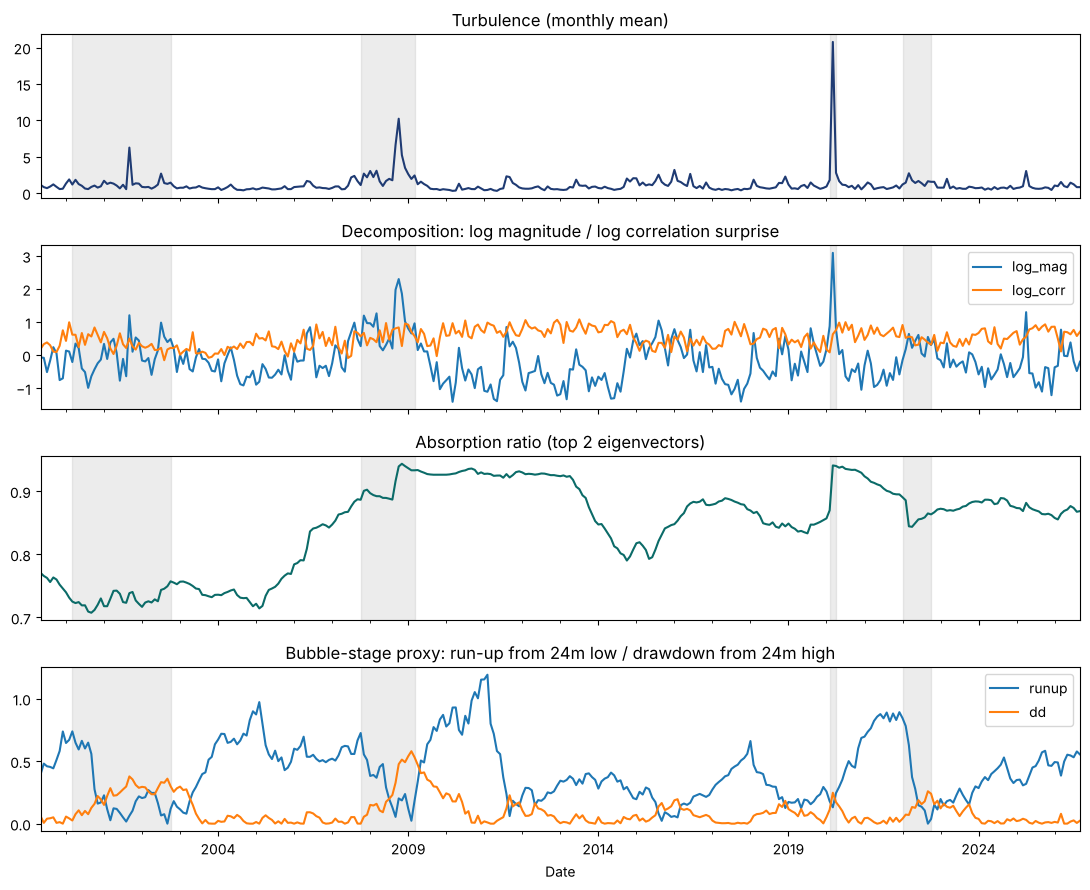

In [3]:
# ===== 2. 상태변수 =====
def turbulence(ret, win=TURB_WIN):
    """Mahalanobis turbulence와 Kinlaw–Turkington 분해(크기·상관 surprise)."""
    X = ret.values; out = np.full((len(X), 3), np.nan)
    for t in range(win, len(X)):
        H = X[t - win:t]; mu = H.mean(0); S = np.cov(H.T)
        d = X[t] - mu
        turb = d @ np.linalg.solve(S, d) / len(d)          # 자산 수로 나눠 정규화
        mag = (d ** 2 / np.diag(S)).sum() / len(d)          # 대각 공분산 = 크기 surprise
        out[t] = turb, mag, turb / mag                      # 비율 = 상관 surprise
    return pd.DataFrame(out, ret.index, ["turb", "mag", "corr"])


def absorption_ratio(ret, win=AR_WIN, hl=AR_HL):
    N = ret.shape[1]; n_eig = max(1, int(np.ceil(N / 5)))  # 자산 수의 약 1/5
    w = 0.5 ** (np.arange(win)[::-1] / hl); w /= w.sum()
    X = ret.values; ar = np.full(len(X), np.nan)
    for t in range(win, len(X)):
        H = X[t - win:t]; Hc = H - w @ H
        S = (Hc * w[:, None]).T @ Hc
        ev = np.sort(np.linalg.eigvalsh(S))[::-1]
        ar[t] = ev[:n_eig].sum() / ev.sum()
    ar = pd.Series(ar, ret.index, name="AR")
    d_ar = (ar.rolling(15).mean() - ar.rolling(250).mean()) / ar.rolling(250).std()
    return ar, d_ar.rename("dAR"), n_eig


def bubble_stage(eq_px):
    """warp 대용: 24개월 저점 대비 상승폭(run-up)과 고점 대비 하락폭.
    원 논문의 dynamic time warping 거품 단계 추정을 단순화한 지표다."""
    lo = eq_px.rolling(504, min_periods=250).min()
    hi = eq_px.rolling(504, min_periods=250).max()
    return pd.DataFrame({"runup": eq_px / lo - 1, "dd": 1 - eq_px / hi})


def build_states(px):
    last = px.index[-1]
    if last < last + pd.offsets.BMonthEnd(0):              # 진행 중인 달은 제외
        px = px[px.index < last.replace(day=1)]
    ret = np.log(px).diff().dropna()
    eq = px[EQ_SLEEVE].pct_change().mean(1); bd = px[BD_SLEEVE].pct_change().mean(1)
    eq_px = (1 + eq.fillna(0)).cumprod()
    T = turbulence(ret); AR, dAR, n_eig = absorption_ratio(ret); B = bubble_stage(eq_px)
    daily = pd.concat([T, dAR, B], axis=1)
    # 월말 상태: turbulence는 그달 평균(잡음 완화), 나머지는 월말 값
    m = pd.concat([daily[["turb", "mag", "corr"]].resample("ME").mean(),
                   daily[["dAR", "runup", "dd"]].resample("ME").last()], axis=1)
    m["log_mag"], m["log_corr"] = np.log(m["mag"]), np.log(m["corr"])
    rets = pd.DataFrame({"eq": (1 + eq).resample("ME").prod() - 1,
                         "bd": (1 + bd).resample("ME").prod() - 1})
    return m.dropna(), rets, AR, n_eig



m, rets, AR, n_eig = build_states(px)
print("월 상태 표본:", m.shape, "| AR 고유벡터 수:", n_eig)

fig, ax = plt.subplots(4, 1, figsize=(11, 9), sharex=True)
m["turb"].plot(ax=ax[0], color="#1f3b73"); ax[0].set_title("Turbulence (monthly mean)")
m[["log_mag", "log_corr"]].plot(ax=ax[1]); ax[1].set_title("Decomposition: log magnitude / log correlation surprise")
AR.resample("ME").last().plot(ax=ax[2], color="#0b6b68"); ax[2].set_title(f"Absorption ratio (top {n_eig} eigenvectors)")
m[["runup", "dd"]].plot(ax=ax[3]); ax[3].set_title("Bubble-stage proxy: run-up from 24m low / drawdown from 24m high")
for a in ax:
    for s, e in [("2000-03", "2002-10"), ("2007-10", "2009-03"), ("2020-02", "2020-04"), ("2022-01", "2022-10")]:
        a.axvspan(s, e, color="grey", alpha=.15)
plt.tight_layout(); plt.show()

## 2. Relevance 예측 (Czasonis·Kritzman·Turkington)

과거 시점 $i$가 현재 $t$와 얼마나 관련 있는지를 다음과 같이 잰다.

$$r_{it}=\underbrace{-\tfrac12(x_i-x_t)^\top\Omega^{-1}(x_i-x_t)}_{\text{유사도}}
+\underbrace{\tfrac12\big[(x_i-\bar x)^\top\Omega^{-1}(x_i-\bar x)+(x_t-\bar x)^\top\Omega^{-1}(x_t-\bar x)\big]}_{\text{정보량}}
=(x_i-\bar x)^\top\Omega^{-1}(x_t-\bar x)$$

- 상위 25%만 남기고(partial sample) $w_i\propto \max(r_{it},0)$로 가중한다 (원 논문의 partial-sample regression을 단순화)
- 조건부 공분산은 희소 상태 대비 무조건부 공분산과 반반 섞어 수축한다
- **fit**: 가중치와 실현 초과수익(주식−채권) 상관의 제곱. 백테스트에서는 fit의 과거 분위수(0~1)를 신뢰도로 쓴다

아래 셀은 가장 최근 월에 대해 relevance가 높은 과거 월 10개를 보여 준다.

In [4]:
# ===== 3. relevance 예측 =====
FEATS = ["log_mag", "log_corr", "dAR", "runup", "dd"]

def relevance_forecast(Xh, Yh, xt, q=Q_KEEP):
    """Xh: 과거 상태(i=1..t-1), Yh: 그 다음 달 실현 수익률, xt: 현재 상태.
    r_it = (x_i - x̄)' Ω^{-1} (x_t - x̄) = 유사도 + 정보량."""
    xbar = Xh.mean(0); Om = np.cov(Xh.T) + 1e-6 * np.eye(Xh.shape[1])
    r = (Xh - xbar) @ np.linalg.solve(Om, xt - xbar)
    keep = r >= np.quantile(r, 1 - q)
    w = np.clip(r[keep], 0, None)                              # 단순화한 partial-sample 가중
    w = w / w.sum() if w.sum() > 0 else np.full(keep.sum(), 1 / keep.sum())
    Yk = Yh[keep]
    mu = w @ Yk; D = Yk - mu; S = (D * w[:, None]).T @ D
    S = 0.5 * S + 0.5 * np.cov(Yh.T)                         # 희소 상태 대비 공분산 수축
    ex = Yk[:, 0] - Yk[:, 1]
    fit = np.corrcoef(w, ex)[0, 1] ** 2 if ex.std() > 0 else 0.0  # 신뢰도(fit)
    return mu, S, float(fit), r



df_all = m.join(rets.shift(-1).add_prefix("next_"), how="inner").dropna()
hist, now = df_all.iloc[:-1], df_all.iloc[-1]
mu, S, fit_raw, r = relevance_forecast(hist[FEATS].values, hist[["next_eq", "next_bd"]].values,
                                       now[FEATS].values.astype(float))
top = hist.assign(relevance=r).nlargest(10, "relevance")[["relevance", "turb", "dAR", "runup", "dd", "next_eq", "next_bd"]]
print("기준월:", df_all.index[-1].date(), "| 조건부 월 기대수익(주식, 채권):", mu.round(4), "| fit:", round(fit_raw, 4))
top.round(3)

기준월: 2026-08-31 | 조건부 월 기대수익(주식, 채권): [0.0128 0.0021] | fit: 0.0149


,relevance,turb,dAR,runup,dd,next_eq,next_bd
Date,,,,,,,
2010-09-30,2.998,0.538,2.040,0.984,0.009,0.034,-0.009
2010-10-31,2.887,0.527,1.028,1.052,0.007,-0.024,-0.010
2010-07-31,2.877,0.558,2.387,0.863,0.080,-0.033,0.036
2006-04-30,2.195,0.919,1.484,0.696,0.000,-0.060,-0.001
2010-08-31,2.186,0.676,2.279,0.801,0.100,0.102,-0.003
2007-09-30,2.164,1.635,1.994,0.666,0.001,0.066,0.013
2007-05-31,2.028,0.544,1.582,0.622,0.000,0.012,-0.007
2017-05-31,2.024,0.543,1.918,0.379,0.004,0.006,0.004
2024-09-30,2.005,0.742,1.937,0.529,0.002,-0.029,-0.034


## 3. 글라이드 패스와 세 전략

- 글라이드: $w_G(\tau)=\text{clip}(0.30+0.02\,\tau,\;0.30,\;0.90)$ — W07 IV 덱과 같은 식(목표일 10년 전 50%)
- 허용 이탈 폭: $b(\tau)=\text{clip}(0.05+0.005\,\tau,\;0.05,\;0.15)$ (20년 이상 ±15%p → 목표일 ±5%p)
- **위험회피 역산**: 무조건부 $\bar\mu,\bar\Sigma$로 평균-분산 최적해가 정확히 $w_G(\tau)$가 되도록 $\lambda(\tau)$를 역산한다. 그러면 조정분은 순수하게 "국면 조건부 정보"에서만 나온다

$$e^*_t=\frac{(\mu_e-\mu_b)-\lambda(\sigma_{eb}-\sigma_b^2)}{\lambda(\sigma_e^2+\sigma_b^2-2\sigma_{eb})},\qquad
\lambda(\tau)=\frac{\bar\mu_e-\bar\mu_b}{w_G(\tau)\,\bar V+\bar\sigma_{eb}-\bar\sigma_b^2}$$

- relevance 연속 전략의 처리 순서
  1. 기대수익 수축: $\mu_c=\bar\mu+0.25(\mu^{rel}-\bar\mu)$
  2. 밴드 압축: $\text{tilt}^{raw}=\text{fit}\cdot b\tanh\!\big((e^*-w_G)/b\big)$
  3. 지수평활: $\text{tilt}_t=0.5\,\text{tilt}_{t-1}+0.5\,\text{tilt}^{raw}_t$
  4. no-trade 밴드: 변화가 2%p 미만이면 매매하지 않음
- 거래비용 편도 10bp, 월말 리밸런싱, 미래 정보는 쓰지 않는다(확장 창)

In [5]:
# ===== 4. 글라이드 패스와 전략 =====
def glide(tau):  return np.clip(0.30 + 0.02 * tau, 0.30, 0.90)       # W07 IV 덱과 동일
def band(tau):   return np.clip(0.05 + 0.005 * tau, 0.05, 0.15)      # 허용 이탈 폭

def mv_equity_weight(mu, S, lam):
    V = S[0, 0] + S[1, 1] - 2 * S[0, 1]
    return ((mu[0] - mu[1]) - lam * (S[0, 1] - S[1, 1])) / (lam * V)

def implied_lambda(mu, S, e):
    """글라이드 비중 e를 최적해로 만드는 위험회피계수(역산)."""
    V = S[0, 0] + S[1, 1] - 2 * S[0, 1]
    den = e * V + S[0, 1] - S[1, 1]
    lam = (mu[0] - mu[1]) / den if den > 0 else np.nan
    return lam if np.isfinite(lam) and lam > 0 else 3.0


def backtest(m, rets, mu_shrink=MU_SHRINK, smooth=SMOOTH):
    df = m.join(rets.shift(-1).add_prefix("next_"), how="inner").dropna()  # i 시점 상태 → i+1 달 수익
    dates = df.index[df.index >= TRADE_FROM]
    tgt = pd.Timestamp(TARGET_DATE)
    rec = []
    w_rel_prev = tilt_prev = None; fits = []
    for t in dates:
        tau = (tgt - t).days / 365.25
        hist = df.loc[:t].iloc[:-1]                       # y_i가 t 시점에 이미 알려진 과거만
        Xh, Yh = hist[FEATS].values, hist[["next_eq", "next_bd"]].values
        xt = df.loc[t, FEATS].values.astype(float)
        wG, b = glide(tau), band(tau)
        # 이진: 확장 창 기준 turbulence 80분위
        thr = df.loc[:t, "turb"].quantile(BINARY_PCT)
        event = df.loc[t, "turb"] > thr
        w_bin = wG - b if event else wG
        # 연속: relevance 조건부 평균-분산 → fit 수축 → 밴드 → no-trade
        mu, S, fit_raw, _ = relevance_forecast(Xh, Yh, xt)
        fits.append(fit_raw)
        fit = (np.array(fits) <= fit_raw).mean() if len(fits) >= 12 else 0.5  # fit의 과거 분위수 = 신뢰도
        mu_bar, S_bar = Yh.mean(0), np.cov(Yh.T)
        lam = implied_lambda(mu_bar, S_bar, wG)
        mu_c = mu_bar + mu_shrink * (mu - mu_bar)            # 기대수익 수축
        e_star = mv_equity_weight(mu_c, S, lam)
        raw_tilt = fit * b * np.tanh((e_star - wG) / b)        # 밴드 안으로 부드럽게 압축
        tilt = raw_tilt if tilt_prev is None else smooth * tilt_prev + (1 - smooth) * raw_tilt
        tilt_prev = tilt
        w_rel = wG + tilt
        if w_rel_prev is not None and abs(w_rel - w_rel_prev) < NO_TRADE:
            w_rel = w_rel_prev
        rec.append(dict(date=t, tau=tau, wG=wG, band=b, event=event, fit=fit,
                        lam=lam, e_star=e_star, w_bin=w_bin, w_rel=w_rel,
                        r_eq=df.loc[t, "next_eq"], r_bd=df.loc[t, "next_bd"]))
        w_rel_prev = w_rel
    R = pd.DataFrame(rec).set_index("date")
    cost = COST_BP / 1e4
    for k in ["wG", "w_bin", "w_rel"]:
        to = R[k].diff().abs().fillna(0)                  # 편도 회전율 = |Δ주식비중|
        R[f"ret_{k}"] = R[k] * R.r_eq + (1 - R[k]) * R.r_bd - to * cost
        R[f"to_{k}"] = to
    return R


def summarize(R):
    rows = {}
    for k, name in [("wG", "정적 글라이드"), ("w_bin", "이진 전환"), ("w_rel", "relevance 연속")]:
        r = R[f"ret_{k}"]; yrs = len(r) / 12
        wealth = (1 + r).cumprod()
        rows[name] = {
            "연수익률": wealth.iloc[-1] ** (1 / yrs) - 1,
            "연변동성": r.std() * np.sqrt(12),
            "샤프(무위험 0)": r.mean() / r.std() * np.sqrt(12),
            "최대낙폭": (wealth / wealth.cummax() - 1).min(),
            "연회전율(편도)": R[f"to_{k}"].sum() / yrs,
            "평균 주식비중": R[k].mean(),
        }
    return pd.DataFrame(rows).T

R = backtest(m, rets)
pd.set_option("display.float_format", "{:.3f}".format)
print("백테스트 구간:", R.index[0].date(), "~", R.index[-1].date(), f"({len(R)}개월)",
      "| 이진 국면 전환 횟수:", int(R.event.astype(int).diff().abs().sum()))
summarize(R)

백테스트 구간: 2002-01-31 ~ 2026-08-31 (296개월) | 이진 국면 전환 횟수: 50


,연수익률,연변동성,샤프(무위험 0),최대낙폭,연회전율(편도),평균 주식비중
정적 글라이드,0.066,0.108,0.648,-0.425,0.020,0.554
이진 전환,0.068,0.101,0.706,-0.362,0.223,0.532
relevance 연속,0.067,0.103,0.677,-0.400,0.167,0.534


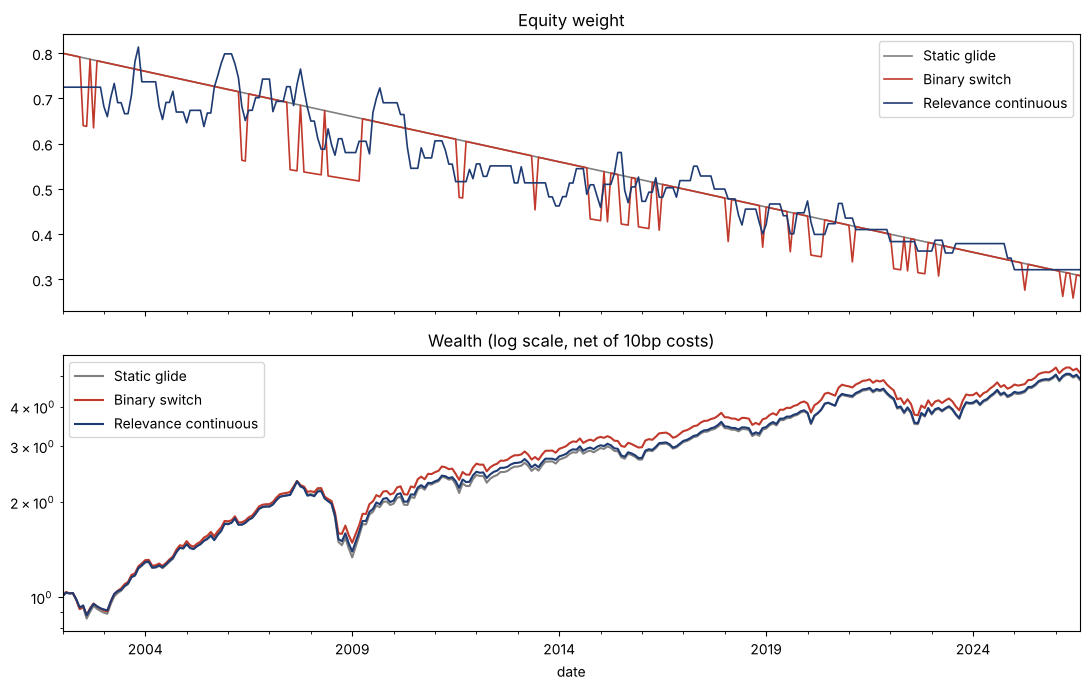

In [6]:
fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
R[["wG", "w_bin", "w_rel"]].plot(ax=ax[0], color=["grey", "#c0392b", "#1f3b73"], lw=1.2)
ax[0].set_title("Equity weight"); ax[0].legend(["Static glide", "Binary switch", "Relevance continuous"])
W = (1 + R[["ret_wG", "ret_w_bin", "ret_w_rel"]]).cumprod()
W.plot(ax=ax[1], color=["grey", "#c0392b", "#1f3b73"], logy=True)
ax[1].set_title("Wealth (log scale, net of 10bp costs)"); ax[1].legend(["Static glide", "Binary switch", "Relevance continuous"])
plt.tight_layout(); plt.show()

## 4. 회전율을 줄이는 것은 무엇인가 — 평활 계수 민감도

연속 반영 자체만으로 회전율이 줄지는 않는다. 조건부 추정치가 매달 흔들리면 오히려 늘 수 있다. 아래 표로 평활 계수(`smooth`)의 효과를 분리한다.

In [7]:
rows = []
for sm in [0.0, 0.3, 0.5, 0.7, 0.85]:
    Rs = backtest(m, rets, MU_SHRINK, sm); Ss = summarize(Rs).loc["relevance 연속"]
    rows.append(dict(smooth=sm, 연회전율=Ss["연회전율(편도)"], 샤프=Ss["샤프(무위험 0)"], 최대낙폭=Ss["최대낙폭"]))
sens = pd.DataFrame(rows).set_index("smooth")
b = summarize(R).loc["이진 전환"]
print(f"비교 기준 — 이진 전환: 회전율 {b['연회전율(편도)']:.3f}, 샤프 {b['샤프(무위험 0)']:.3f}, 최대낙폭 {b['최대낙폭']:.3f}")
sens

비교 기준 — 이진 전환: 회전율 0.223, 샤프 0.706, 최대낙폭 -0.362


,연회전율,샤프,최대낙폭
smooth,,,
0.000,0.411,0.675,-0.402
0.300,0.250,0.677,-0.402
0.500,0.167,0.677,-0.400
0.700,0.085,0.675,-0.398
0.850,0.035,0.667,-0.406


## 5. 위기 구간 성과

In [8]:
crises = {"GFC": ("2007-10", "2009-03"), "COVID": ("2020-01", "2020-04"), "2022 금리": ("2022-01", "2022-10")}
pd.DataFrame({c: {name: (1 + R.loc[a:b_, f"ret_{k}"]).prod() - 1
                  for k, name in [("wG", "정적"), ("w_bin", "이진"), ("w_rel", "relevance")]}
              for c, (a, b_) in crises.items()})

,GFC,COVID,2022 금리
정적,-0.327,-0.014,-0.134
이진,-0.276,-0.011,-0.143
relevance,-0.308,-0.019,-0.136


## 6. 해석 (2026년 10월 실행 기준, yfinance 실데이터)

| | 정적 | 이진 | relevance 연속 |
|---|---|---|---|
| 샤프 | 0.65 | **0.71** | 0.68 |
| 최대낙폭 | −43% | **−36%** | −40% |
| 연회전율 | 2% | 22% | **17%** |

1. **회전율**: 연속 반영은 평활을 넣었을 때만 이진 전환보다 낮다. 평활 없이(`smooth=0`) 쓰면 회전율이 41%로 이진보다 높다. 앞선 논의의 "연속 반영 → 회전율 감소"는 조건부 추정치를 평활·수축한다는 전제에서만 성립한다.
2. **위기 방어**: GFC 구간 손실은 이진(−28%) < relevance(−31%) < 정적(−33%) 순이었다. turbulence 단독 이진 신호가 급성 위기에는 더 빠르게 반응했다.
3. **조정 폭**: fit 분위수 × 밴드 × tanh 압축이 겹쳐 글라이드 대비 이탈은 평균 3.8%p, 최대 12%p다. 위기 직후 반등기(2009~2010)에 비중을 늘린 것이 이진 전략과 다른 점이다.
4. **2022 금리 충격**: 주식·채권이 함께 떨어져 세 전략 모두 방어하지 못했다. 안전자산 슬리브가 국채·회사채뿐인 구조적 한계다.

**다음 실험 후보**
- 이진 신호와 relevance를 결합: 급성 위기는 turbulence 이진, 평시 미세조정은 relevance
- 상태변수 조합·$q$를 adjusted fit으로 고르고 홀드아웃 구간에서 검증
- 안전자산 슬리브에 현금·TIPS 추가 (2022형 충격 대응)

> 수치는 실행 시점의 데이터에 따라 조금 달라질 수 있다.